# Mini-Project 5 — Taxi Route Revenue, Pricing & Fleet Planner

**Scenario.** A matatu association runs 14-seater taxis on three routes out of Kampala and wants to forecast demand, understand fares and decide how many vehicles to deploy.

**Data.** Daily passenger counts over 10 days: Kampala–Ntinda from the original question, Entebbe and Mukono illustrative. Fares are UGX 2,000, 5,000 and 3,000.

**Assumption.** The counts are read as **one-way passengers per day** on each route. That is small for a Kampala route, so they probably represent a sampled stage or time window. I flag where this changes the fleet answer.

Code: `src/taxi.py` (`Route`, equilibrium, fleet sizing) plus the shared forecaster hierarchy in `src/forecasting.py`, also used by Mini-Project 1.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.forecasting import (ExponentialSmoothingForecaster, LinearTrendForecaster, MovingAverageForecaster,
                             SeasonalNaiveForecaster, walk_forward)
from src.metrics import mae
from src.taxi import Route, market_equilibrium, simulate_weekly_demand, vehicles_needed

SEED = 2026
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. The `Route` class

In [2]:
routes = [
    Route("Kampala–Ntinda",  [35, 40, 42, 50, 55, 60, 48, 52, 47, 45], 2_000),
    Route("Kampala–Entebbe", [60, 58, 65, 70, 72, 80, 75, 68, 66, 64], 5_000),
    Route("Kampala–Mukono",  [45, 47, 50, 49, 55, 62, 58, 53, 51, 50], 3_000),
]
rows = []
for r in routes:
    s = r.describe()
    rows.append({"route": r.name, "fare (UGX)": r.fare, "mean pax/day": s["mean"], "variance": s["variance"],
                 "SD": s["stdev"], "CV": s["stdev"] / s["mean"], "mean revenue/day (UGX)": r.daily_revenue().mean(),
                 "10-day revenue (UGX)": r.total_revenue()})
display(pd.DataFrame(rows).set_index("route"))
print(routes[0], "| Day-1 revenue check: 35 × 2,000 =", f"{routes[0].daily_revenue()[0]:,.0f}")

,fare (UGX),mean pax/day,variance,SD,CV,mean revenue/day (UGX),10-day revenue (UGX)
route,,,,,,,
Kampala–Ntinda,"2,000.00",47.40,54.27,7.37,0.16,"94,800.00","948,000.00"
Kampala–Entebbe,"5,000.00",67.80,45.07,6.71,0.10,"339,000.00","3,390,000.00"
Kampala–Mukono,"3,000.00",52.00,26.44,5.14,0.10,"156,000.00","1,560,000.00"


Route('Kampala–Ntinda', days=10, fare=UGX 2,000) | Day-1 revenue check: 35 × 2,000 = 70,000


Entebbe carries the most passengers **and** the highest fare, so it earns about 3.6× Ntinda's revenue. Ntinda is the most variable route relative to its size (CV 0.16): it grew steadily from 35 to 60 passengers and then fell back.

## 2. Supply–demand equilibrium on the Ntinda route
Demand Q_d = 120 − 0.02P and supply Q_s = 10 + 0.03P (Q in passengers per trip-hour, P in UGX). Writing both with unknowns [Q, P]:

$$\begin{bmatrix}1 & 0.02\\ 1 & -0.03\end{bmatrix}\begin{bmatrix}Q\\P\end{bmatrix} = \begin{bmatrix}120\\10\end{bmatrix}$$

In [3]:
p_star, q_star = market_equilibrium(demand=(120, -0.02), supply=(10, 0.03))
print(f"Equilibrium fare P* = UGX {p_star:,.0f}, quantity Q* = {q_star:.0f} passengers per trip-hour")
print("Hand check: 120 − 0.02P = 10 + 0.03P → 110 = 0.05P → P = 2,200; Q = 120 − 44 = 76")
P = 2_000
qd, qs = 120 - 0.02 * P, 10 + 0.03 * P
print(f"At the current UGX {P:,}: demand = {qd:.0f}, supply = {qs:.0f} → excess demand of {qd - qs:.0f} passengers per trip-hour")

Equilibrium fare P* = UGX 2,200, quantity Q* = 76 passengers per trip-hour
Hand check: 120 − 0.02P = 10 + 0.03P → 110 = 0.05P → P = 2,200; Q = 120 − 44 = 76
At the current UGX 2,000: demand = 80, supply = 70 → excess demand of 10 passengers per trip-hour


**Interpretation.** The current fare of UGX 2,000 is **UGX 200 below** equilibrium. At that price, 80 passengers want a seat each trip-hour but operators are only willing to supply 70, a shortage of 10. On the ground that looks like queues at the stage, full taxis passing waiting passengers, and conductors informally charging more at peak times. Raising the fare to UGX 2,200 would clear the market; the alternative is adding capacity so the supply curve shifts right. Fares are politically sensitive, so the association may prefer the capacity route, and the fleet plan below addresses that.

## 3–4. Forecasters and walk-forward backtesting (days 4–10)
Each model is a `Forecaster` subclass: `MovingAverageForecaster(3)` (the original method), `ExponentialSmoothingForecaster(α)` and `LinearTrendForecaster`. For every origin day *t* = 4…10, a fresh model is fitted on days 1…*t*−1 and forecasts day *t* (rolling origin, no look-ahead).

**Tuning α.** Grid search over α ∈ {0.05, 0.10, …, 1.00}, picking the α with the lowest backtest MAE per route.

In [4]:
ALPHAS = np.round(np.arange(0.05, 1.0001, 0.05), 2)
START = 3        # 0-based index of day 4

grid_rows, results, best_alpha = [], {}, {}
for r in routes:
    y = r.passengers
    alpha_mae = {a: mae(*walk_forward(lambda a=a: ExponentialSmoothingForecaster(a), y, START)) for a in ALPHAS}
    best_alpha[r.name] = min(alpha_mae, key=alpha_mae.get)
    grid_rows.append(pd.Series(alpha_mae, name=r.name))
    models = {"3-day moving average": lambda: MovingAverageForecaster(3),
              f"SES (α={best_alpha[r.name]:.2f}, tuned)": lambda a=best_alpha[r.name]: ExponentialSmoothingForecaster(a),
              "Linear trend": LinearTrendForecaster}
    results[r.name] = {name: walk_forward(f, y, START) for name, f in models.items()}

alpha_table = pd.DataFrame(grid_rows)
display(alpha_table.iloc[:, ::3].rename_axis("MAE by α (every 3rd α shown)"))
mae_table = pd.DataFrame({route: {m.split(" (")[0]: mae(*res[m]) for m in res} for route, res in results.items()}).T
mae_table["best model"] = mae_table.idxmin(axis=1)
mae_table["tuned α"] = [best_alpha[r] for r in mae_table.index]
display(mae_table.rename_axis("walk-forward MAE (passengers), days 4–10"))

,0.05,0.2,0.35,0.5,0.65,0.8,0.95
MAE by α (every 3rd α shown),,,,,,,
Kampala–Ntinda,13.03,7.94,7.22,6.72,6.27,5.97,5.86
Kampala–Entebbe,8.82,7.13,6.85,6.04,5.54,5.06,4.58
Kampala–Mukono,7.36,5.08,4.86,4.38,3.97,3.86,3.76


,3-day moving average,SES,Linear trend,best model,tuned α
"walk-forward MAE (passengers), days 4–10",,,,,
Kampala–Ntinda,7.52,5.86,7.87,SES,1.00
Kampala–Entebbe,7.19,4.43,7.71,SES,1.00
Kampala–Mukono,5.33,3.71,6.39,SES,1.00


In [5]:
a, p = results["Kampala–Ntinda"]["3-day moving average"]
print("Hand check, Ntinda MA(3) forecast for day 4 = (35+40+42)/3 =", round(p[0], 2), "| actual", a[0])

Hand check, Ntinda MA(3) forecast for day 4 = (35+40+42)/3 = 39.0 | actual 50.0


**Reading the results.** Tuned SES wins on every route, but notice where α lands: exactly **1.0** on all three routes. SES with α = 1 *is* the naive forecast, "tomorrow equals today". So the honest finding is that, over seven test days, the most recent observation beats both a 3-day average (which lags behind the trend) and a straight line (which overreacts to a short series that rises, then falls). Two cautions apply. First, α was tuned on the same seven days it is scored on, so the SES error is **optimistic**; a fair test would tune on one window and score on another, but ten days is too short to split. Second, a difference of 1–2 passengers in MAE over seven forecasts is weak evidence.

## 5. Day-11 forecast and actual vs forecast revenue

,model,day-11 passengers,day-11 revenue (UGX)
route,,,
Kampala–Ntinda,SES,45.00,"90,000.00"
Kampala–Entebbe,SES,64.00,"320,000.00"
Kampala–Mukono,SES,50.00,"150,000.00"


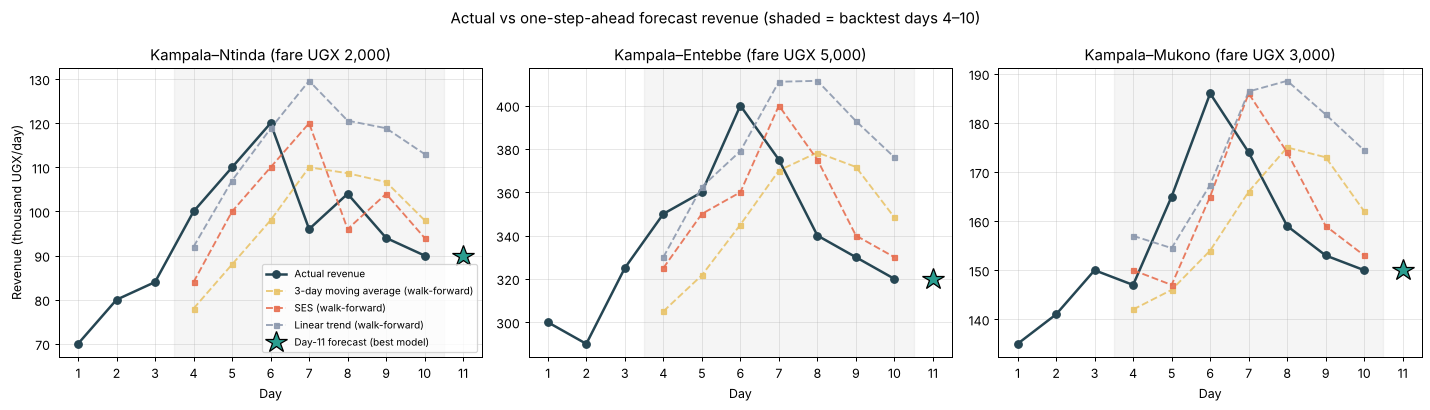

In [6]:
fc_rows = []
for r in routes:
    best_name = mae_table.loc[r.name, "best model"]
    factory = {"3-day moving average": lambda: MovingAverageForecaster(3),
               "SES": lambda: ExponentialSmoothingForecaster(best_alpha[r.name]),
               "Linear trend": LinearTrendForecaster}[best_name]
    pax11 = factory().fit(r.passengers).predict(1)[0]
    fc_rows.append({"route": r.name, "model": best_name, "day-11 passengers": pax11,
                    "day-11 revenue (UGX)": pax11 * r.fare})
fc11 = pd.DataFrame(fc_rows).set_index("route")
display(fc11)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True)
days = np.arange(1, 11)
for ax, r in zip(axes, routes):
    ax.plot(days, r.daily_revenue() / 1000, "o-", color="#264653", lw=2, label="Actual revenue")
    for (name, (act, pred)), col in zip(results[r.name].items(), ["#e9c46a", "#e76f51", "#8d99ae"]):
        ax.plot(days[START:], pred * r.fare / 1000, "s--", ms=4, color=col, alpha=0.9, label=f"{name.split(' (')[0]} (walk-forward)")
    ax.plot(11, fc11.loc[r.name, "day-11 revenue (UGX)"] / 1000, "*", ms=18, color="#2a9d8f", mec="black",
            label="Day-11 forecast (best model)")
    ax.axvspan(3.5, 10.5, color="grey", alpha=0.08)
    ax.set(title=f"{r.name} (fare UGX {r.fare:,.0f})", xlabel="Day", xticks=range(1, 12))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Revenue (thousand UGX/day)")
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Actual vs one-step-ahead forecast revenue (shaded = backtest days 4–10)")
fig.tight_layout()
fig.savefig("figures/p5_revenue_forecasts.png", dpi=150)
plt.show()

## 6. Fleet planning for day 11
Each vehicle makes 8 one-way trips a day × 14 seats = **112 passenger-trips/day**. Vehicles = ⌈forecast × 1.15 / 112⌉: add a 15% buffer, then round **up**, because a fraction of a taxi cannot be deployed and rounding down would guarantee a shortfall.

In [7]:
fleet = fc11[["day-11 passengers"]].copy()
fleet["with 15% buffer"] = fleet["day-11 passengers"] * 1.15
fleet["seat-trips per vehicle"] = 8 * 14
fleet["vehicles"] = [vehicles_needed(p) for p in fleet["day-11 passengers"]]
fleet["load factor if deployed"] = fleet["day-11 passengers"] / (fleet["vehicles"] * 112)
display(fleet)
peak = {r.name: r.passengers.max() for r in routes}
print("Vehicles needed even on each route's busiest observed day:", {k: vehicles_needed(v) for k, v in peak.items()})

,day-11 passengers,with 15% buffer,seat-trips per vehicle,vehicles,load factor if deployed
route,,,,,
Kampala–Ntinda,45.00,51.75,112,1,0.40
Kampala–Entebbe,64.00,73.60,112,1,0.57
Kampala–Mukono,50.00,57.50,112,1,0.45


Vehicles needed even on each route's busiest observed day: {'Kampala–Ntinda': 1, 'Kampala–Entebbe': 1, 'Kampala–Mukono': 1}


On the numbers as given, **one vehicle per route** covers day 11, with room to spare: load factors are about 40–60%. Rounding up already provides more slack than the 15% buffer. That conclusion depends on the unit assumption, though. If the counts are a *sample*, for example one stage or one hour, the same formula scales directly: at 10× the counts, Entebbe would need ⌈~650 × 1.15 / 112⌉ = 7 vehicles. The equilibrium analysis also suggests demand is being suppressed by a shortage at UGX 2,000, so observed counts may understate true demand on Ntinda.

## Extension — 60 days with a weekly cycle: seasonal-naïve vs moving average
Synthetic, seeded data with a weekly pattern (day 1 = Monday): Fridays ×1.35 (busiest), Saturdays ×1.10, Sundays ×0.60 (quietest), weekdays ≈ ×1.0, plus noise. Both models are walk-forward tested on days 15–60.

Mean passengers by weekday: {'Mon': 50.6, 'Tue': 48.2, 'Wed': 49.4, 'Thu': 54.2, 'Fri': 70.2, 'Sat': 54.2, 'Sun': 30.6}


,"MAE (passengers), days 15–60"
3-day moving average,9.59
Seasonal naïve (m=7),3.22
SES (α=0.95),11.82


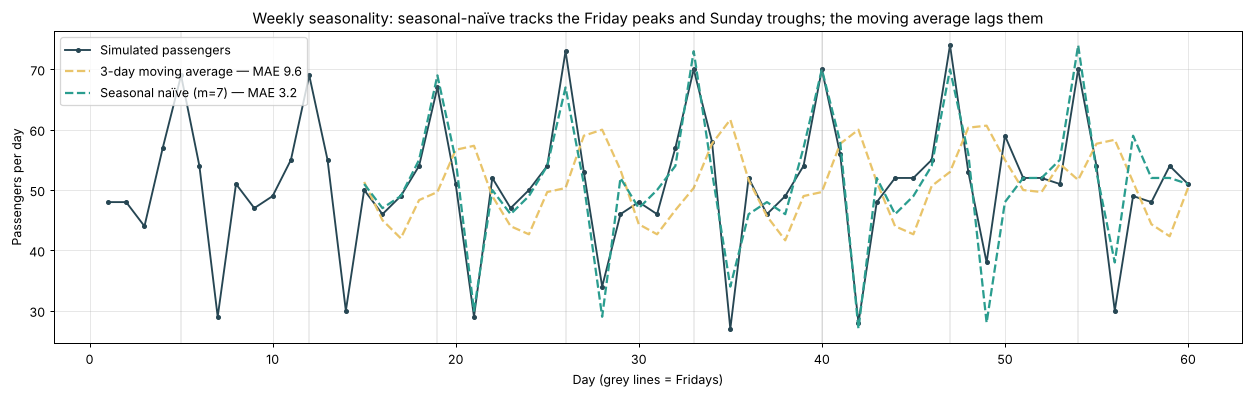

In [8]:
y60 = simulate_weekly_demand(days=60, base=50, seed=SEED)
weekday_means = pd.Series(y60).groupby(np.arange(60) % 7).mean()
weekday_means.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("Mean passengers by weekday:", weekday_means.round(1).to_dict())

ext_models = {"3-day moving average": lambda: MovingAverageForecaster(3),
              "Seasonal naïve (m=7)": lambda: SeasonalNaiveForecaster(7),
              "SES (α=0.95)": lambda: ExponentialSmoothingForecaster(0.95)}
ext = {name: walk_forward(f, y60, 14) for name, f in ext_models.items()}
ext_mae = pd.Series({name: mae(*v) for name, v in ext.items()}, name="MAE (passengers), days 15–60")
display(ext_mae.to_frame())

fig, ax = plt.subplots(figsize=(14, 4.5))
d60 = np.arange(1, 61)
ax.plot(d60, y60, "o-", color="#264653", ms=3, label="Simulated passengers")
for (name, (_, pred)), col in zip(ext.items(), ["#e9c46a", "#2a9d8f", "#e76f51"]):
    if "SES" in name:
        continue
    ax.plot(d60[14:], pred, "--", color=col, lw=1.8, label=f"{name} — MAE {ext_mae[name]:.1f}")
for fri in d60[(d60 - 1) % 7 == 4]:
    ax.axvline(fri, color="grey", alpha=0.15)
ax.set(xlabel="Day (grey lines = Fridays)", ylabel="Passengers per day",
       title="Weekly seasonality: seasonal-naïve tracks the Friday peaks and Sunday troughs; the moving average lags them")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/p5_seasonal_extension.png", dpi=150)
plt.show()

The seasonal-naïve forecaster cuts the error by roughly two-thirds. A 3-day moving average is systematically wrong about the weekly cycle: it forecasts Friday from Tuesday–Thursday (too low), Sunday from Thu–Sat including the busy Friday (far too high), and Monday from the weekend (too low). Seasonal-naïve forecasts each day from the same weekday last week, so it captures the cycle by construction. Its remaining error is just the day-level noise. On the original 10-day data there is too little history to see a weekly cycle, which is why it could not be used there.

## Findings & Limitations

**Findings.** Entebbe is the association's most valuable route, earning about UGX 339,000 a day, roughly 3.6× Ntinda, because it combines the highest fare with the most passengers. On Ntinda the fare of UGX 2,000 is about UGX 200 below the UGX 2,200 equilibrium, which creates an excess demand of roughly 10 passengers per trip-hour. The association can either raise fares slightly or add capacity, and observed ridership there probably understates true demand. In walk-forward testing, SES tuned to α = 1, which is exactly the naive "same as yesterday" forecast, beat both the original 3-day moving average and the linear trend on all three routes. The moving average lags turning points, and a trend line fitted to ten volatile days overreacts. Day-11 forecasts are 45, 64 and 50 passengers, so one 14-seater per route is enough even with the 15% buffer and on each route's busiest observed day. The extension shows the bigger lesson for real operations: with weekly seasonality, a seasonal-naïve model cuts error by about two-thirds compared with the moving average, so forecasting should be done by weekday once enough history exists.

**Limitations.** Ten days is far too short to tell the models apart reliably. α was tuned on the same days it was scored on, so SES's advantage is optimistic. The demand and supply curves are given, not estimated, and they treat fares as the only lever, ignoring traffic, fuel prices and competition from boda-bodas. The passenger counts are probably samples, so the absolute fleet numbers should be rescaled with real daily totals. Trips per day also depend heavily on Kampala traffic. The 60-day weekly pattern is synthetic and illustrates the method, not real ridership.